In [3]:
import pandas as pd
import numpy as np


In [6]:
df=pd.read_csv('IMDB Dataset.csv')

In [7]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [8]:
df.shape

(50000, 2)

In [11]:
df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [12]:
df.isnull().sum()

,0
review,0
sentiment,0


In [14]:
df['sentiment'].value_counts()

,count
sentiment,
positive,25000
negative,25000


In [15]:
import nltk
import re
import string

from nltk.corpus import stopwords
from nltk.tokenize import wordpunct_tokenize
from nltk.stem import WordNetLemmatizer

In [17]:
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [18]:
stop_words = set(stopwords.words('english'))
stop_words = stop_words - {'no', 'not', 'nor'}

In [19]:
lemmatizer = WordNetLemmatizer()

In [30]:
def preprocess(review):
  text = str(review).lower()
  text = re.sub(r"n't\b", " not", review)
  text = text.translate(str.maketrans('', '', string.punctuation))
  words = wordpunct_tokenize(review)
  words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words and word.isalpha()]

  return ' '.join(words)

In [31]:
df = df.dropna(subset=['review', 'sentiment']).copy()

df['clean_review'] = df['review'].apply(preprocess)

df[['review', 'clean_review']].head()

,review,clean_review
0,One of the other reviewers has mentioned that ...,One reviewer mentioned watching Oz episode hoo...
1,A wonderful little production. <br /><br />The...,A wonderful little production br br The filmin...
2,I thought this was a wonderful way to spend ti...,I thought wonderful way spend time hot summer ...
3,Basically there's a family where a little boy ...,Basically family little boy Jake think zombie ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",Petter Mattei Love Time Money visually stunnin...


In [34]:
x=df['review']
y=df['sentiment']

In [38]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=42,stratify=y)

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

x_train_tfidf = tfidf.fit_transform(x_train)
x_test_tfidf = tfidf.transform(x_test)

In [42]:
from sklearn.linear_model import LogisticRegression

LR= LogisticRegression(max_iter=1000)

LR.fit(x_train_tfidf, y_train)
y_pred=LR.predict(x_test_tfidf)

In [46]:
y_pred = LR.predict(x_test_tfidf)

print(y_pred[:10])

['negative' 'positive' 'positive' 'negative' 'negative' 'negative'
 'negative' 'negative' 'negative' 'negative']


In [48]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred,average='weighted')

print("Accuracy:", accuracy)
print("F1 Score:", f1)

print(classification_report(y_test, y_pred))

Accuracy: 0.8931
F1 Score: 0.893097638526835
              precision    recall  f1-score   support

    negative       0.90      0.89      0.89      5000
    positive       0.89      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [51]:
feature_names = np.array(tfidf.get_feature_names_out())

classes = LR.classes_
coefficients = LR.coef_

for i, class_name in enumerate(classes):

    if len(classes) == 2:
        # Binary logistic regression stores one coefficient vector
        scores = coefficients[0] if i == 1 else -coefficients[0]
    else:
        scores = coefficients[i]

    top_indices = np.argsort(scores)[-10:][::-1]

    print(f"\nTop 10 words for {class_name}:")
    print(feature_names[top_indices])


Top 10 words for negative:
['worst' 'bad' 'waste' 'awful' 'boring' 'terrible' 'poor' 'dull' 'nothing'
 'horrible']

Top 10 words for positive:
['great' 'excellent' 'perfect' 'amazing' 'best' 'wonderful' 'loved'
 'hilarious' 'enjoyed' 'brilliant']


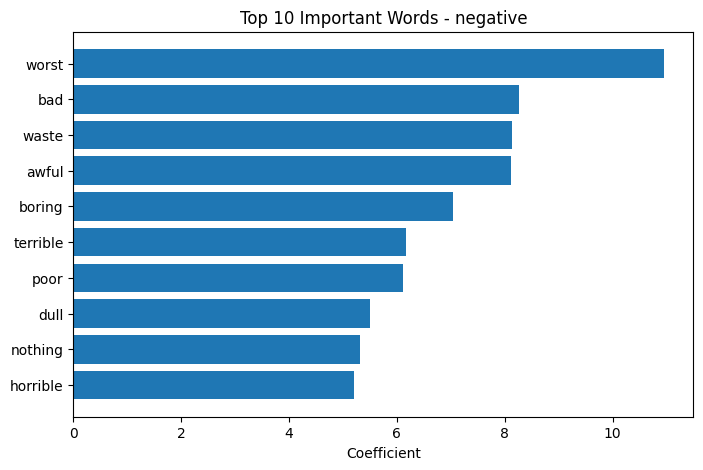

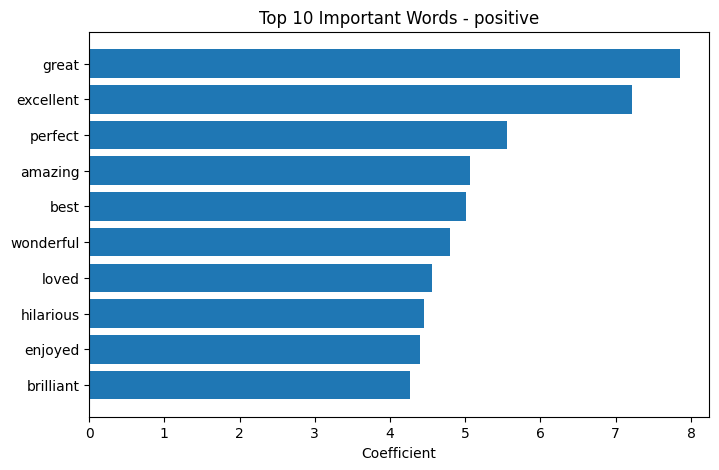

In [52]:
import matplotlib.pyplot as plt

for i, class_name in enumerate(classes):

    if len(classes) == 2:
        scores = coefficients[0] if i == 1 else -coefficients[0]
    else:
        scores = coefficients[i]

    top_indices = np.argsort(scores)[-10:]

    plt.figure(figsize=(8, 5))

    plt.barh(
        feature_names[top_indices],
        scores[top_indices]
    )

    plt.xlabel('Coefficient')
    plt.title(f'Top 10 Important Words - {class_name}')
    plt.show()

### Sentiment Classification — Conclusion

In this task, I developed a sentiment classification model using Natural Language Processing techniques.

First, I preprocessed the text by converting it to lowercase, removing punctuation and stopwords, tokenizing the text, and applying lemmatization.

Next, I used TF-IDF vectorization to convert the cleaned text into numerical features. I split the dataset into training and testing sets and trained a Logistic Regression model to predict sentiment labels.

I evaluated the model using Accuracy and weighted F1-score to measure its classification performance.

Finally, I identified the top 10 most important words for each sentiment class using the model's learned feature coefficients.

**Results:**
- Accuracy: 0.8931
- Weighted F1-score: 0.893097638526835


The results demonstrate how text preprocessing and TF-IDF features can be combined with supervised machine learning to classify sentiment.